# 📰 DATA BERITA EKONOMI — BAB 4.1.2
## Tesis: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi LQ45
**Mahasiswa :** Ilda Nurida (NRP 6032251068)
**Prodi      :** Magister Manajemen Teknologi — SIMT ITS
**Tahun      :** 2026

---
### 🗂️ Output yang Dihasilkan Notebook Ini
| Cell | Output | Kegunaan Tesis |
|------|--------|----------------|
| Cell 1 | Konfigurasi & Library | Setup |
| Cell 2 | Load & Gabung CSV | Dataset gabungan |
| Cell 3 | **Tabel 4.2** — Sampel artikel per sumber | Bukti scraping |
| Cell 4 | **Tabel 4.3** — Rekap artikel per sumber | Tabel tesis |
| Cell 5 | **Tabel 4.4** — Distribusi per emiten × sumber | Tabel tesis |
| Cell 6 | **Gambar 4.2** — Grafik artikel per emiten | Gambar tesis |
| Cell 7 | **Gambar 4.3** — Grafik artikel per tahun | Gambar tesis |
| Cell 8 | **Gambar 4.4** — Word cloud per emiten | Gambar tesis |
| Cell 9 | Simpan dataset final | Input IndoBERT |

---
## ⚙️ CELL 1 — Import Library dan Konfigurasi

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
import os
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.family' : 'Times New Roman',
    'font.size'   : 11,
    'figure.dpi'  : 150,
})

# ═══════════════════════════════════════════════════════════
# PATH — DETEKSI OTOMATIS
# ═══════════════════════════════════════════════════════════
NOTEBOOK_DIR = os.getcwd()
KANDIDAT_PATH = [
    os.path.join(NOTEBOOK_DIR, 'raw'),
    os.path.join(NOTEBOOK_DIR, '03_dataset', 'raw'),
    os.path.join(NOTEBOOK_DIR),
    os.path.join(NOTEBOOK_DIR, '..', 'raw'),
    os.path.join(NOTEBOOK_DIR, '..', '03_dataset', 'raw'),
]

BASE_DIR = None
for kandidat in KANDIDAT_PATH:
    kandidat = os.path.abspath(kandidat)
    if os.path.exists(kandidat):
        isi = os.listdir(kandidat)
        if any('berita_' in f and f.endswith('.csv') for f in isi):
            BASE_DIR = kandidat
            break

if BASE_DIR is None:
    BASE_DIR = r'GANTI_MANUAL_DISINI'
    print('⚠️  Isi BASE_DIR secara manual!')
else:
    print(f'✅ BASE_DIR : {BASE_DIR}')

OUTPUT_DIR = os.path.join(os.path.dirname(BASE_DIR), 'final')
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f'✅ OUTPUT   : {OUTPUT_DIR}')

# ── Mapping file sumber (hanya 5 sumber yang berhasil)
FILE_SUMBER = {
    'Detik Finance' : 'berita_detik_lq45_energi.csv',
    'Kontan'        : 'berita_kontan_lq45_energi.csv',
    'Antara'        : 'berita_antara_lq45_energi.csv',
    'Bloomberg'     : 'berita_bloomberg_lq45_energi.csv',
    'CNBC'          : 'berita_cnbc_lq45_energi.csv',
}

KOLOM_STANDAR = ['Sumber', 'Kode_Emiten', 'Keyword', 'Headline', 'Tanggal', 'Link', 'Isi_Berita']
URUTAN_EMITEN = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']

NAMA_PERUSAHAAN = {
    'ADRO': 'Adaro Energy Indonesia Tbk',
    'ADMR': 'Adaro Minerals Indonesia Tbk',
    'ITMG': 'Indo Tambangraya Megah Tbk',
    'PTBA': 'Bukit Asam Tbk',
    'MEDC': 'Medco Energi Internasional Tbk',
    'AKRA': 'AKR Corporindo Tbk',
    'PGAS': 'Perusahaan Gas Negara Tbk',
}

WARNA_SUMBER = {
    'Detik Finance' : '#1f77b4',
    'Kontan'        : '#2ca02c',
    'Antara'        : '#ff7f0e',
    'Bloomberg'     : '#d62728',
    'CNBC'          : '#9467bd',
}
WARNA_EMITEN = {
    'ADRO':'#1f77b4','ADMR':'#2ca02c','ITMG':'#ff7f0e',
    'PTBA':'#d62728','MEDC':'#9467bd','AKRA':'#8c564b','PGAS':'#e377c2',
}

print('\n✅ Konfigurasi selesai.')

✅ BASE_DIR : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\raw
✅ OUTPUT   : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final

✅ Konfigurasi selesai.


---
## 📂 CELL 2 — Load, Standarisasi, dan Gabungkan Semua CSV

In [3]:
RENAME_MAP = {
    'Emiten':'Kode_Emiten','emiten':'Kode_Emiten','kode_emiten':'Kode_Emiten',
    'URL':'Link','url':'Link','link':'Link',
    'headline':'Headline','title':'Headline','Title':'Headline',
    'tanggal':'Tanggal','date':'Tanggal','Date':'Tanggal',
    'isi_berita':'Isi_Berita','content':'Isi_Berita','isi':'Isi_Berita',
    'keyword':'Keyword','sumber':'Sumber',
}

list_df = []

print('=' * 65)
print('  📂 LOAD SEMUA FILE CSV BERITA')
print('=' * 65)

for nama_sumber, nama_file in FILE_SUMBER.items():
    path_file = os.path.join(BASE_DIR, nama_file)
    if not os.path.exists(path_file):
        print(f'  ⚠️  TIDAK DITEMUKAN : {nama_file}')
        continue
    try:
        df_temp = pd.read_csv(path_file, encoding='utf-8-sig', low_memory=False)
    except Exception as e:
        print(f'  ❌ GAGAL LOAD : {nama_file} → {e}')
        continue

    df_temp.rename(columns={k:v for k,v in RENAME_MAP.items() if k in df_temp.columns}, inplace=True)
    df_temp['Sumber'] = nama_sumber

    # Auto-cari kolom Tanggal jika belum ada
    if 'Tanggal' not in df_temp.columns:
        cari = [c for c in df_temp.columns if any(k in c.lower() for k in ['tanggal','tgl','date','time','published'])]
        if cari:
            df_temp.rename(columns={cari[0]:'Tanggal'}, inplace=True)

    for kol in KOLOM_STANDAR:
        if kol not in df_temp.columns:
            df_temp[kol] = ''

    df_temp = df_temp[KOLOM_STANDAR].copy()

    # Coba parse tanggal dengan beberapa format
    for fmt in [None, '%d/%m/%Y', '%Y/%m/%d', '%d-%m-%Y']:
        try:
            df_temp['Tanggal'] = pd.to_datetime(df_temp['Tanggal'],
                                                format=fmt, errors='coerce')
            if df_temp['Tanggal'].notna().mean() > 0.5:
                break
        except Exception:
            continue

    sebelum = len(df_temp)
    df_temp.dropna(subset=['Tanggal'], inplace=True)
    sesudah = len(df_temp)

    if sesudah == 0:
        print(f'  ❌ {nama_sumber}: semua Tanggal NaT — skip')
        continue

    list_df.append(df_temp)
    tgl_min = df_temp['Tanggal'].min()
    tgl_max = df_temp['Tanggal'].max()
    print(f'  ✅ {nama_sumber:<18}: {sesudah:>5,} artikel '
          f'| {tgl_min.strftime("%d %b %Y") if pd.notna(tgl_min) else "N/A"} → '
          f'{tgl_max.strftime("%d %b %Y") if pd.notna(tgl_max) else "N/A"}')

# ── Gabung dan deduplikasi
df_gabung = pd.concat(list_df, ignore_index=True)
sebelum_dedup = len(df_gabung)
df_gabung.drop_duplicates(subset=['Link'], keep='first', inplace=True)
df_gabung.sort_values('Tanggal', ascending=False, inplace=True)
df_gabung.reset_index(drop=True, inplace=True)

# ── Kolom bantu
df_gabung['Tahun']    = df_gabung['Tanggal'].dt.year
df_gabung['Bulan_dt'] = df_gabung['Tanggal'].dt.to_period('M').dt.to_timestamp()

print()
print(f'  ✅ TOTAL GABUNGAN    : {len(df_gabung):,} artikel')
print(f'  Duplikat dibuang    : {sebelum_dedup - len(df_gabung):,}')
print(f'  Periode             : {df_gabung["Tanggal"].min().strftime("%d %b %Y")} → '
      f'{df_gabung["Tanggal"].max().strftime("%d %b %Y")}')
print(f'  Jumlah sumber aktif : {df_gabung["Sumber"].nunique()}')

  📂 LOAD SEMUA FILE CSV BERITA
  ✅ Detik Finance     : 1,286 artikel | 01 Jan 2022 → 30 Jun 2026
  ✅ Kontan            : 5,911 artikel | 03 Jan 2022 → 30 Jun 2026
  ✅ Antara            : 1,803 artikel | 04 Jan 2022 → 30 Jun 2026
  ✅ Bloomberg         :   233 artikel | 01 Feb 2023 → 11 Jun 2026
  ✅ CNBC              : 1,019 artikel | 02 Jan 2022 → 29 Jun 2026

  ✅ TOTAL GABUNGAN    : 9,280 artikel
  Duplikat dibuang    : 972
  Periode             : 01 Jan 2022 → 30 Jun 2026
  Jumlah sumber aktif : 5


---
## 📰 CELL 3 — Tabel 4.2: Sampel Artikel Terbaru per Sumber (Bukti Scraping)

In [4]:
from IPython.display import display, HTML

print('=' * 65)
print('  📰 TABEL 4.2 — SAMPEL 1 ARTIKEL TERBARU PER SUMBER')
print('=' * 65)

list_sampel = []
for sumber in FILE_SUMBER.keys():
    df_src = df_gabung[df_gabung['Sumber'] == sumber].sort_values('Tanggal', ascending=False)
    if df_src.empty:
        continue
    art = df_src.iloc[0]
    list_sampel.append({
        'Sumber'         : sumber,
        'Emiten'         : art['Kode_Emiten'],
        'Tanggal'        : pd.to_datetime(art['Tanggal']).strftime('%d/%m/%Y'),
        'Title/Headline' : str(art['Headline'])[:80],
        'Text Content'   : ' '.join(str(art['Isi_Berita']).split()[:20]) + '...',
    })

df_tabel42 = pd.DataFrame(list_sampel)
df_tabel42.index = range(1, len(df_tabel42)+1)
df_tabel42.index.name = 'No'

display(HTML(df_tabel42.to_html(border=1)))

# Simpan
path_t42 = os.path.join(OUTPUT_DIR, 'tabel_4_2_sampel_artikel.csv')
df_tabel42.to_csv(path_t42, encoding='utf-8-sig')
print(f'\n  💾 Tabel 4.2 disimpan: {path_t42}')

  📰 TABEL 4.2 — SAMPEL 1 ARTIKEL TERBARU PER SUMBER


,Sumber,Emiten,Tanggal,Title/Headline,Text Content
No,,,,,
1,Detik Finance,PGAS,30/06/2026,PGN Pastikan Siap Terapkan Kebijakan Pemerintah soal Harga Gas Industri,Pemerintah memastikan kebutuhan gas bumi bagi sektor industri tetap terpenuhi dengan harga yang lebih kompetitif melalui sejumlah penyesuaian kebijakan. Langkah...
2,Kontan,ADRO,30/06/2026,Lonjakan Harga Batubara Memacu Laju Saham Emiten Grup Alamtri,-JAKARTA. Harga saham emiten pertambangan batubara Grup Alamtri melaju kencang di sepanjang tahun berjalan 2026. Yang paling mentereng adalah saham...
3,Antara,PGAS,30/06/2026,Kemenperin tekankan optimisme industri kuat meski hadapi tantangan,Jakarta (ANTARA) - Kementerian Perindustrian (Kemenperin) menegaskan optimisme pelaku industri manufaktur nasional tetap terjaga meski sektor tersebut menghadapi tantangan yang...
4,Bloomberg,PTBA,21/05/2026,Target Harga Saham BUMN Tambang Usai Purbaya Sarankan SerokMarket| 21 May 2026 1,"Bloomberg Technoz, Jakarta- Menteri Keuangan Purbaya Yudhi Sadewa mengatakan ‘it’s time to buy’ saham-saham emiten pertambangan Badan Usaha Milik Negara..."
5,CNBC,PGAS,29/06/2026,"Harga Gas LNG untuk Industri Diturunkan Jadi US$ 13, PGN Buka Suara","Jakarta, CNBC Indonesia -PT Perusahaan Gas Negara (Persero) Tbk (PGN) mengungkapkan kesiapan dalam melaksanakan kebijakan pemerintah terkait harga gas bumi,..."



  💾 Tabel 4.2 disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final\tabel_4_2_sampel_artikel.csv


---
## 📋 CELL 4 — Tabel 4.3: Rekap Jumlah Artikel per Sumber

In [5]:
print('=' * 65)
print('  📋 TABEL 4.3 — REKAP JUMLAH ARTIKEL PER SUMBER')
print('=' * 65)

rekap = (
    df_gabung.groupby('Sumber')
    .agg(
        Jumlah_Artikel = ('Headline', 'count'),
        Periode_Awal   = ('Tanggal',  'min'),
        Periode_Akhir  = ('Tanggal',  'max'),
    )
    .reset_index()
    .sort_values('Jumlah_Artikel', ascending=False)
    .reset_index(drop=True)
)
rekap.index = range(1, len(rekap)+1)
rekap.index.name = 'No'

total_artikel = rekap['Jumlah_Artikel'].sum()
rekap['Persentase (%)'] = (rekap['Jumlah_Artikel'] / total_artikel * 100).round(1)
rekap['Periode_Awal']   = rekap['Periode_Awal'].dt.strftime('%d %b %Y')
rekap['Periode_Akhir']  = rekap['Periode_Akhir'].dt.strftime('%d %b %Y')

# Baris total
baris_total = pd.DataFrame([{
    'Sumber'         : 'TOTAL',
    'Jumlah_Artikel' : total_artikel,
    'Periode_Awal'   : '-',
    'Periode_Akhir'  : '-',
    'Persentase (%)' : 100.0,
}])
df_tabel43 = pd.concat([rekap, baris_total], ignore_index=True)

print(df_tabel43.to_string(index=False))

path_t43 = os.path.join(OUTPUT_DIR, 'tabel_4_3_rekap_per_sumber.csv')
df_tabel43.to_csv(path_t43, index=False, encoding='utf-8-sig')
print(f'\n  💾 Tabel 4.3 disimpan: {path_t43}')

  📋 TABEL 4.3 — REKAP JUMLAH ARTIKEL PER SUMBER
       Sumber  Jumlah_Artikel Periode_Awal Periode_Akhir  Persentase (%)
       Kontan            5405  03 Jan 2022   30 Jun 2026            58.2
       Antara            1715  04 Jan 2022   30 Jun 2026            18.5
Detik Finance            1074  01 Jan 2022   30 Jun 2026            11.6
         CNBC             967  02 Jan 2022   29 Jun 2026            10.4
    Bloomberg             119  01 Feb 2023   21 May 2026             1.3
        TOTAL            9280            -             -           100.0

  💾 Tabel 4.3 disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final\tabel_4_3_rekap_per_sumber.csv


---
## 📋 CELL 5 — Tabel 4.4: Distribusi Artikel per Emiten × Sumber

In [6]:
print('=' * 65)
print('  📋 TABEL 4.4 — DISTRIBUSI ARTIKEL PER EMITEN × SUMBER')
print('=' * 65)

df_valid = df_gabung[df_gabung['Kode_Emiten'].isin(URUTAN_EMITEN)].copy()

pivot = df_valid.pivot_table(
    index        = 'Sumber',
    columns      = 'Kode_Emiten',
    values       = 'Headline',
    aggfunc      = 'count',
    fill_value   = 0,
    margins      = True,
    margins_name = 'Total',
)

# Urutkan kolom
kolom_urut = [e for e in URUTAN_EMITEN if e in pivot.columns] + ['Total']
pivot = pivot.reindex(columns=kolom_urut, fill_value=0)

print(pivot.to_string())

path_t44 = os.path.join(OUTPUT_DIR, 'tabel_4_4_distribusi_per_emiten_sumber.csv')
pivot.to_csv(path_t44, encoding='utf-8-sig')
print(f'\n  💾 Tabel 4.4 disimpan: {path_t44}')

  📋 TABEL 4.4 — DISTRIBUSI ARTIKEL PER EMITEN × SUMBER
Kode_Emiten    ADRO  ADMR  ITMG  PTBA  MEDC  AKRA  PGAS  Total
Sumber                                                        
Antara          260     9    51   451   284    54   606   1715
Bloomberg        49     8    10    26    11     4    11    119
CNBC            269    25    54   269    94    44   212    967
Detik Finance   228    26    12   259   188    39   322   1074
Kontan         1031   297   524   883   821   689  1160   5405
Total          1837   365   651  1888  1398   830  2311   9280

  💾 Tabel 4.4 disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final\tabel_4_4_distribusi_per_emiten_sumber.csv


---
## 📊 CELL 6 — Gambar 4.2: Grafik Jumlah Artikel per Emiten per Sumber

📊 Membuat Gambar 4.2 — Artikel per Emiten...


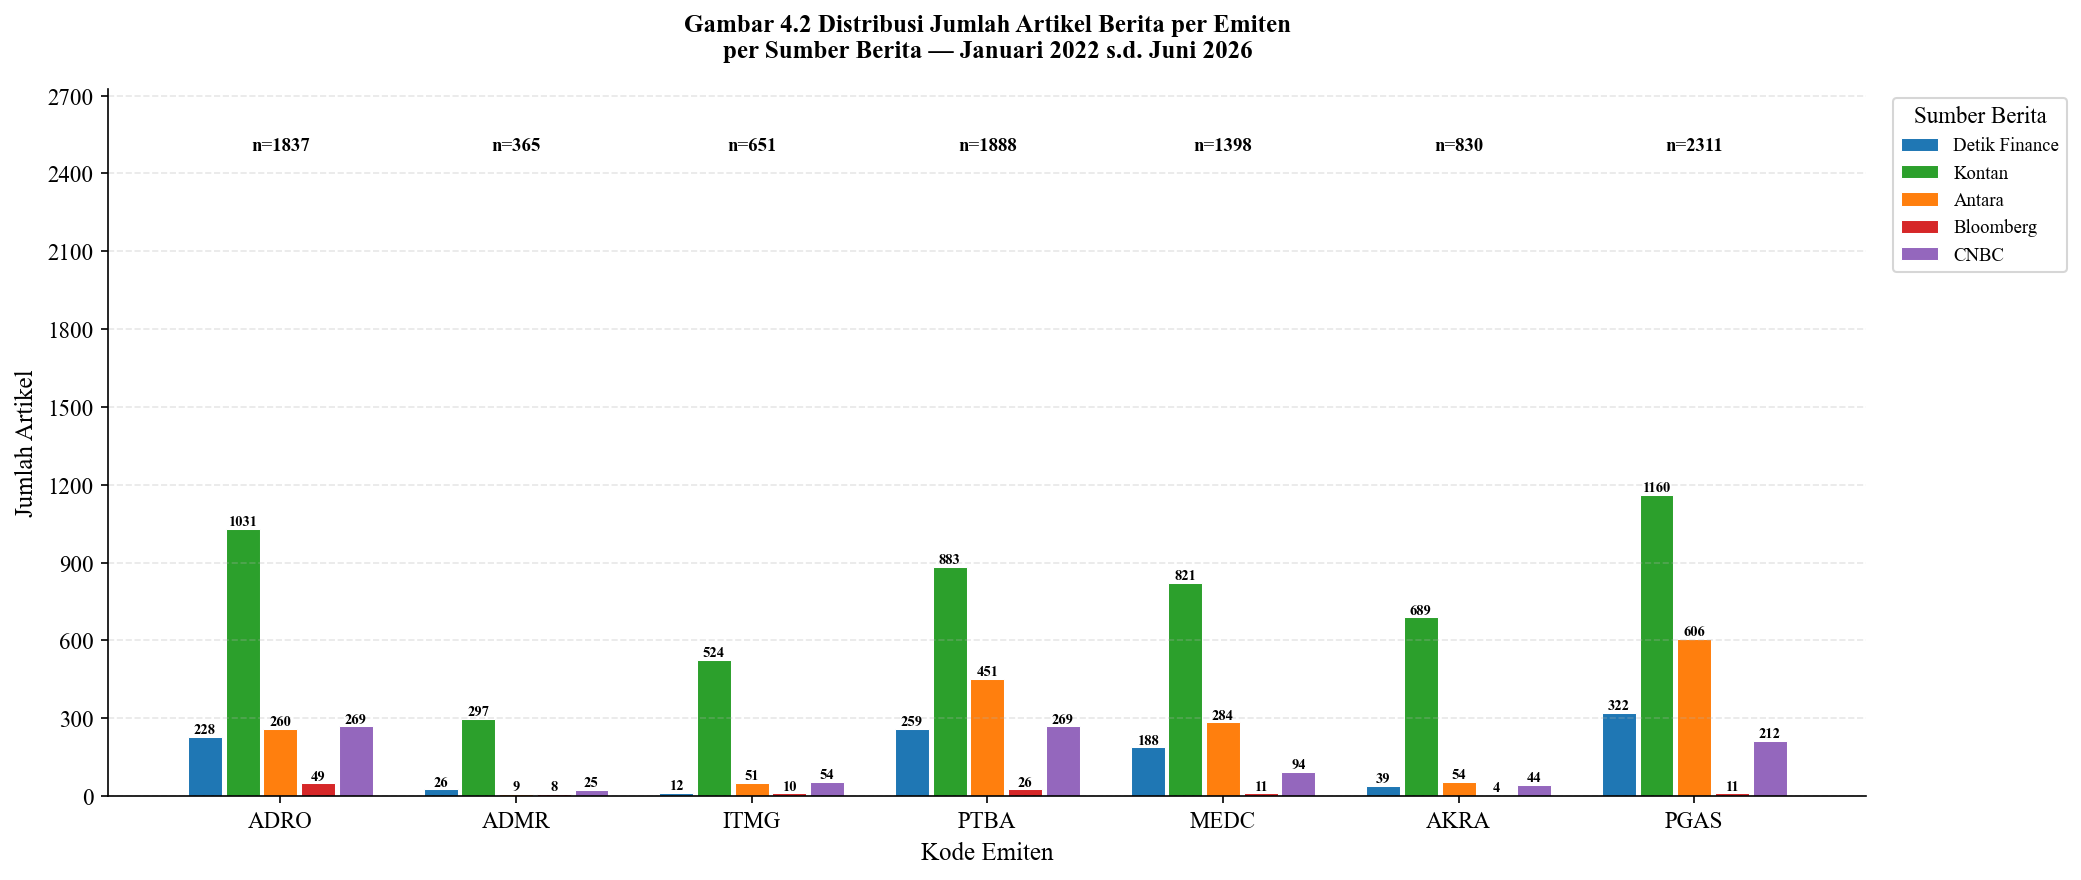

  ✅ Gambar 4.2 disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final\gambar_4_2_artikel_per_emiten.png


In [7]:
print('📊 Membuat Gambar 4.2 — Artikel per Emiten...')

df_plot1    = df_valid.groupby(['Sumber','Kode_Emiten']).size().reset_index(name='Jumlah')
sumber_list = [s for s in FILE_SUMBER.keys() if s in df_plot1['Sumber'].unique()]
emiten_list = [e for e in URUTAN_EMITEN if e in df_plot1['Kode_Emiten'].unique()]

n_s   = len(sumber_list)
n_e   = len(emiten_list)
x     = np.arange(n_e)
lebar = 0.8 / n_s

fig1, ax1 = plt.subplots(figsize=(14, 6))

for i, sumber in enumerate(sumber_list):
    df_s   = df_plot1[df_plot1['Sumber'] == sumber].set_index('Kode_Emiten')
    nilai  = [int(df_s.loc[e,'Jumlah']) if e in df_s.index else 0 for e in emiten_list]
    offset = (i - n_s/2 + 0.5) * lebar
    bars   = ax1.bar(x + offset, nilai, width=lebar*0.9,
                     label=sumber, color=WARNA_SUMBER.get(sumber,'#aaa'),
                     edgecolor='white', linewidth=0.5)
    for bar, val in zip(bars, nilai):
        if val > 0:
            ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.8,
                     str(val), ha='center', va='bottom', fontsize=7, fontweight='bold')

# Total per emiten
total_e = df_plot1.groupby('Kode_Emiten')['Jumlah'].sum().reindex(emiten_list, fill_value=0)
for j, (em, tot) in enumerate(total_e.items()):
    ax1.text(x[j], total_e.max()*1.07, f'n={int(tot)}',
             ha='center', va='bottom', fontsize=9, fontweight='bold')

ax1.set_xticks(x)
ax1.set_xticklabels(emiten_list, fontsize=11)
ax1.set_xlabel('Kode Emiten', fontsize=12)
ax1.set_ylabel('Jumlah Artikel', fontsize=12)
ax1.set_title(
    'Gambar 4.2 Distribusi Jumlah Artikel Berita per Emiten\n'
    'per Sumber Berita — Januari 2022 s.d. Juni 2026',
    fontsize=12, fontweight='bold', pad=15
)
ax1.legend(title='Sumber Berita', bbox_to_anchor=(1.01,1), loc='upper left', fontsize=9)
ax1.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax1.grid(axis='y', alpha=0.3, linestyle='--')
ax1.spines[['top','right']].set_visible(False)
ax1.set_ylim(0, total_e.max()*1.18)

plt.tight_layout()
path_g42 = os.path.join(OUTPUT_DIR, 'gambar_4_2_artikel_per_emiten.png')
plt.savefig(path_g42, dpi=200, bbox_inches='tight')
plt.show()
print(f'  ✅ Gambar 4.2 disimpan: {path_g42}')

---
## 📊 CELL 7 — Gambar 4.3: Grafik Jumlah Artikel per Tahun

📊 Membuat Gambar 4.3 — Artikel per Tahun...


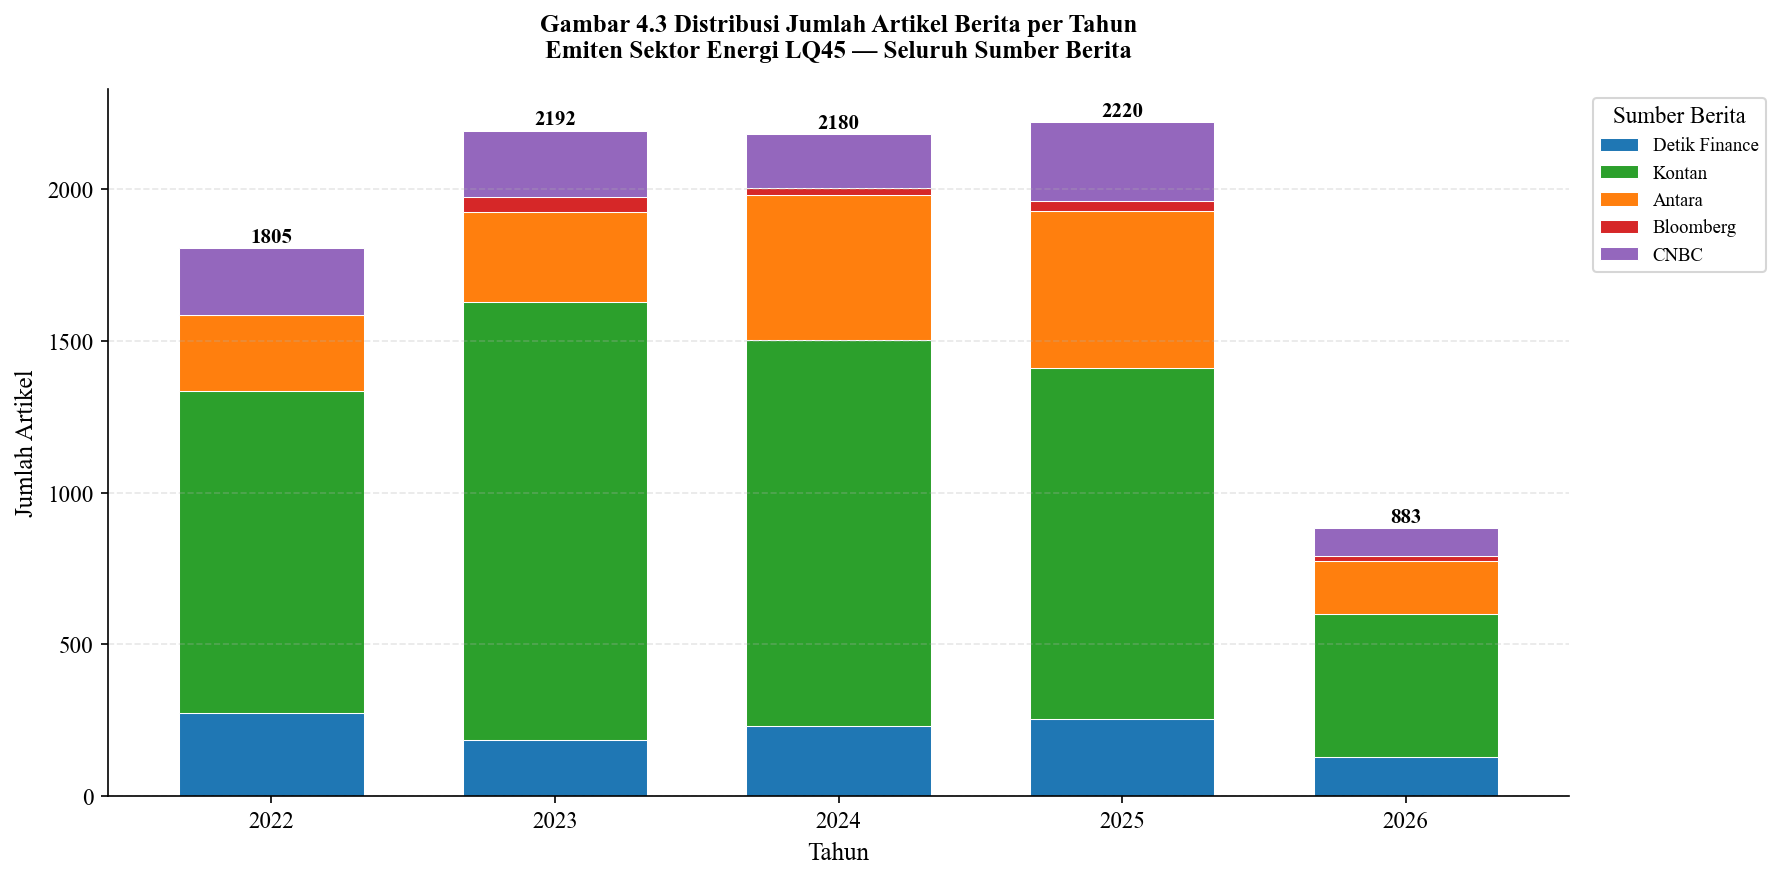

  ✅ Gambar 4.3 disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final\gambar_4_3_artikel_per_tahun.png


In [8]:
print('📊 Membuat Gambar 4.3 — Artikel per Tahun...')

sumber_aktif = [s for s in FILE_SUMBER.keys() if s in df_gabung['Sumber'].unique()]

df_tahun = (
    df_gabung.groupby(['Tahun','Sumber'])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=sumber_aktif, fill_value=0)
)

warna_list = [WARNA_SUMBER.get(s,'#aaa') for s in sumber_aktif]

fig2, ax2 = plt.subplots(figsize=(12, 6))
df_tahun.plot(kind='bar', stacked=True, ax=ax2,
              color=warna_list, edgecolor='white', linewidth=0.5, width=0.65)

# Label total
totals = df_tahun.sum(axis=1)
for idx, (thn, tot) in enumerate(totals.items()):
    ax2.text(idx, tot+3, str(int(tot)),
             ha='center', va='bottom', fontsize=10, fontweight='bold')

ax2.set_xlabel('Tahun', fontsize=12)
ax2.set_ylabel('Jumlah Artikel', fontsize=12)
ax2.set_title(
    'Gambar 4.3 Distribusi Jumlah Artikel Berita per Tahun\n'
    'Emiten Sektor Energi LQ45 — Seluruh Sumber Berita',
    fontsize=12, fontweight='bold', pad=15
)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=0, fontsize=11)
ax2.legend(title='Sumber Berita', bbox_to_anchor=(1.01,1), loc='upper left', fontsize=9)
ax2.grid(axis='y', alpha=0.3, linestyle='--')
ax2.spines[['top','right']].set_visible(False)

plt.tight_layout()
path_g43 = os.path.join(OUTPUT_DIR, 'gambar_4_3_artikel_per_tahun.png')
plt.savefig(path_g43, dpi=200, bbox_inches='tight')
plt.show()
print(f'  ✅ Gambar 4.3 disimpan: {path_g43}')

---
## 📊 CELL 8 — Gambar 4.4: Word Cloud Isi Berita per Emiten


[notice] A new release of pip available: 22.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


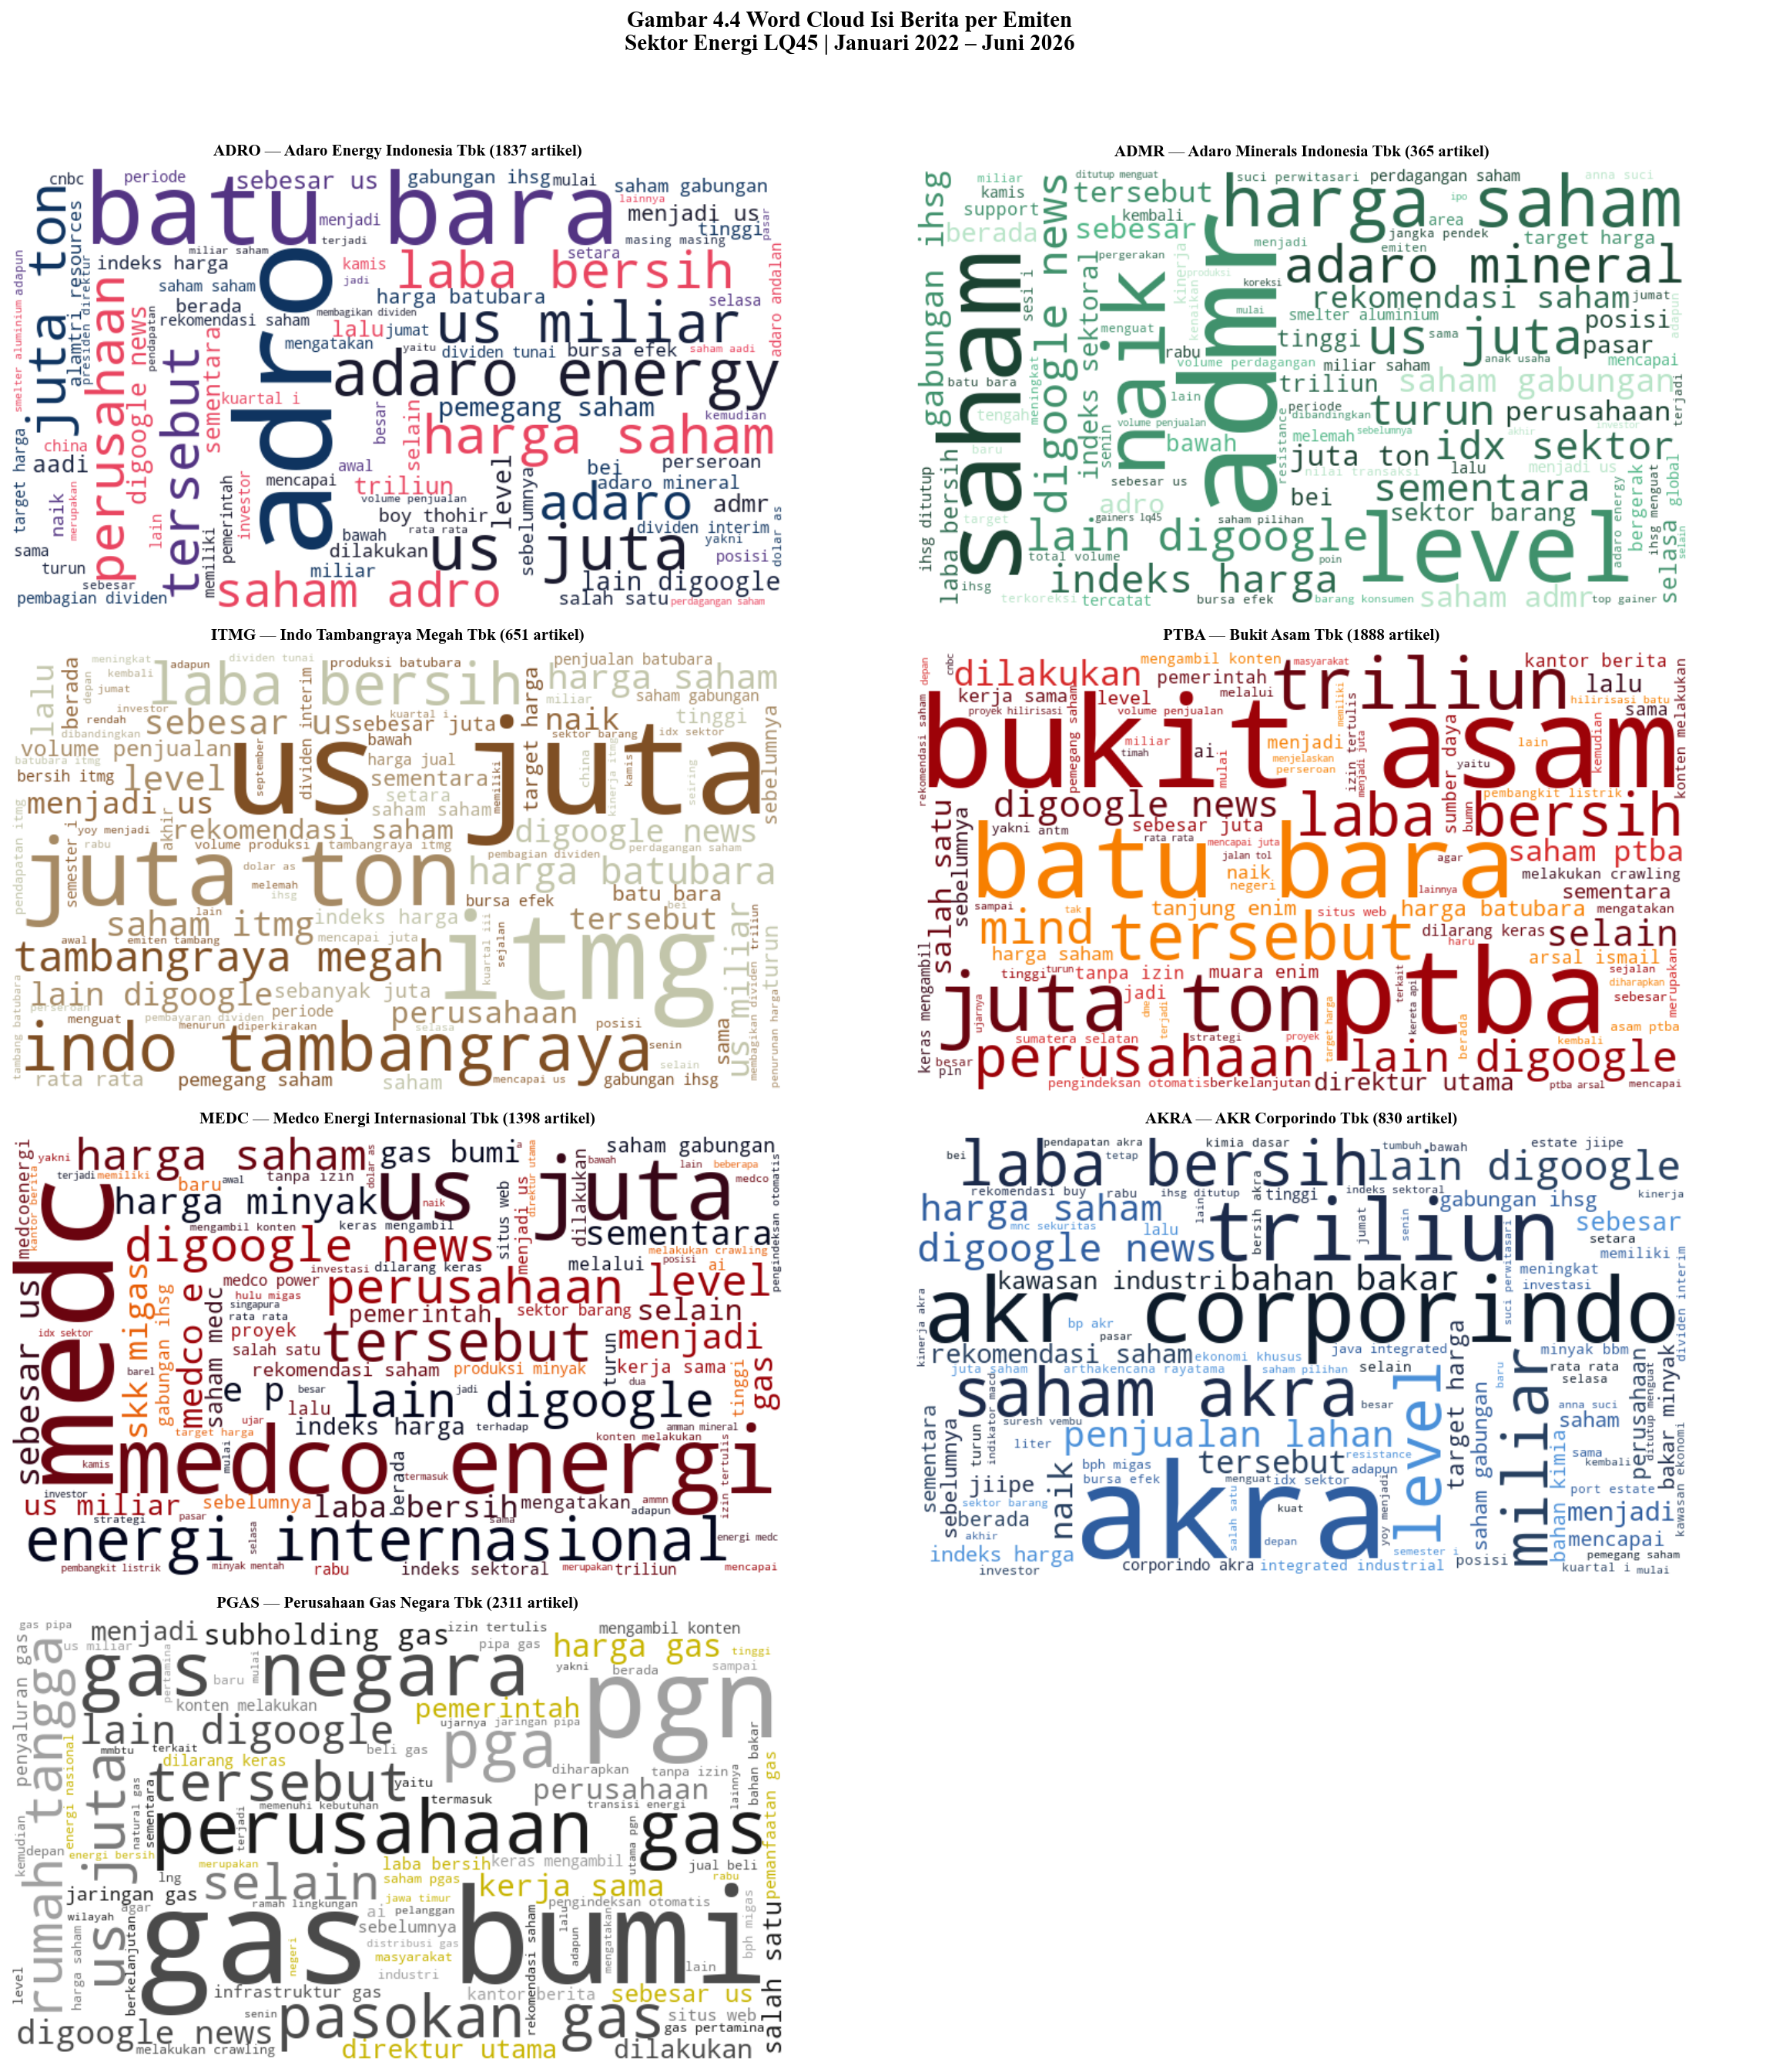

  ✅ Gambar 4.4 disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final\gambar_4_4_wordcloud_per_emiten.png


In [9]:
!pip install wordcloud -q
from wordcloud import WordCloud

PALET_WARNA = {
    'ADRO': ['#1a1a2e','#16213e','#0f3460','#533483','#e94560'],
    'ADMR': ['#1b4332','#2d6a4f','#40916c','#52b788','#b7e4c7'],
    'ITMG': ['#7f4f24','#936639','#a68a64','#b6ad90','#c2c5aa'],
    'PTBA': ['#370617','#6a040f','#9d0208','#d62828','#f77f00'],
    'MEDC': ['#03071e','#370617','#6a040f','#9d0208','#e85d04'],
    'AKRA': ['#0d1b2a','#1b2a4a','#274060','#2e5d9f','#4a90d9'],
    'PGAS': ['#1a1a1a','#4a4a4a','#7a7a7a','#a0a0a0','#c8b400'],
}

STOPWORDS_ID = {
    'yang','dan','di','ke','dari','ini','itu','dengan','untuk',
    'pada','adalah','dalam','tidak','juga','akan','sebagai','oleh',
    'atau','telah','sudah','dapat','bisa','ada','saat','tahun',
    'kata','serta','kami','kita','mereka','dia','ia','lebih',
    'namun','karena','sehingga','hal','jika','maka','antara',
    'baik','secara','seperti','ketika','setelah','sebelum','hingga',
    'sejak','selama','masih','hanya','sangat','pun',
    'tbk','pt','rp','persen','per','senilai','sekitar',
    'detik','finance','com','co','id','jakarta','indonesia',
    'said','the','to','of','in','and','atas','bahwa',
    'baca','juga','cek','sini','simak','hari','ini','kontan',
}

def make_color_func(palette):
    def color_func(word, font_size, position, orientation, random_state=None, **kwargs):
        return palette[random_state.randint(0, len(palette)-1)]
    return color_func

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()
MIN_ARTIKEL = 5

for i, kode in enumerate(URUTAN_EMITEN):
    ax = axes[i]
    df_em = df_gabung[df_gabung['Kode_Emiten'] == kode]
    n = len(df_em)

    if n < MIN_ARTIKEL:
        ax.text(0.5,0.5,f'Data terlalu sedikit\n({n} artikel)',
                ha='center',va='center',transform=ax.transAxes,fontsize=11,color='gray')
        ax.set_title(f'{kode} — {NAMA_PERUSAHAAN.get(kode,kode)}',fontweight='bold',fontsize=10)
        ax.axis('off'); continue

    teks = ' '.join(df_em['Isi_Berita'].dropna().astype(str).str.lower().tolist())
    if not teks.strip():
        ax.text(0.5,0.5,f'Isi berita kosong',ha='center',va='center',transform=ax.transAxes)
        ax.axis('off'); continue

    try:
        wc = WordCloud(
            width=700, height=400, background_color='white',
            stopwords=STOPWORDS_ID, max_words=100, min_font_size=8,
            max_font_size=120, collocations=True, prefer_horizontal=0.7,
            relative_scaling=0.6, color_func=make_color_func(PALET_WARNA[kode])
        ).generate(teks)
        ax.imshow(wc, interpolation='bilinear')
        ax.set_title(f'{kode} — {NAMA_PERUSAHAAN.get(kode,kode)} ({n} artikel)',
                     fontweight='bold', fontsize=10, pad=8)
        ax.axis('off')
    except ValueError:
        ax.text(0.5,0.5,f'Teks terlalu sedikit\n({n} artikel)',
                ha='center',va='center',transform=ax.transAxes,fontsize=10,color='gray')
        ax.axis('off')

axes[-1].axis('off')
fig.suptitle(
    'Gambar 4.4 Word Cloud Isi Berita per Emiten\n'
    'Sektor Energi LQ45 | Januari 2022 – Juni 2026',
    fontsize=14, fontweight='bold', y=0.995
)
fig.tight_layout(rect=[0,0,1,0.97])
path_g44 = os.path.join(OUTPUT_DIR, 'gambar_4_4_wordcloud_per_emiten.png')
fig.savefig(path_g44, dpi=200, bbox_inches='tight')
plt.show()
print(f'  ✅ Gambar 4.4 disimpan: {path_g44}')

---
## 💾 CELL 9 — Simpan Dataset Gabungan Final (Input IndoBERT)

In [10]:
print('=' * 65)
print('  💾 SIMPAN DATASET GABUNGAN FINAL')
print('=' * 65)

df_final = df_gabung[KOLOM_STANDAR].copy()
df_final['Tanggal'] = df_final['Tanggal'].dt.strftime('%Y-%m-%d')

path_final = os.path.join(OUTPUT_DIR, 'berita_gabungan_semua_sumber_FINAL.csv')
df_final.to_csv(path_final, index=False, encoding='utf-8-sig')

print(f'  ✅ File tersimpan   : {path_final}')
print(f'  Total artikel      : {len(df_final):,}')
print(f'  Kolom              : {list(df_final.columns)}')
print()
print('  Preview 5 artikel terbaru:')
display(HTML(df_final[['Sumber','Kode_Emiten','Tanggal','Headline']].head().to_html(border=1)))
print()
print('=' * 65)
print('  ✅ SELESAI — BAB 4.1.2 Data Berita Ekonomi')
print()
print('  📌 RINGKASAN OUTPUT:')
print(f'     Tabel 4.2 (sampel artikel)    → tabel_4_2_sampel_artikel.csv')
print(f'     Tabel 4.3 (rekap per sumber)  → tabel_4_3_rekap_per_sumber.csv')
print(f'     Tabel 4.4 (per emiten×sumber) → tabel_4_4_distribusi_per_emiten_sumber.csv')
print(f'     Gambar 4.2 (per emiten)       → gambar_4_2_artikel_per_emiten.png')
print(f'     Gambar 4.3 (per tahun)        → gambar_4_3_artikel_per_tahun.png')
print(f'     Gambar 4.4 (word cloud)       → gambar_4_4_wordcloud_per_emiten.png')
print(f'     Dataset Final IndoBERT        → berita_gabungan_semua_sumber_FINAL.csv')
print()
print('  📌 LANGKAH SELANJUTNYA:')
print('     → Jalankan notebook INDOBERT_SENTIMEN.ipynb')
print('       menggunakan: berita_gabungan_semua_sumber_FINAL.csv')
print('=' * 65)

  💾 SIMPAN DATASET GABUNGAN FINAL
  ✅ File tersimpan   : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final\berita_gabungan_semua_sumber_FINAL.csv
  Total artikel      : 9,280
  Kolom              : ['Sumber', 'Kode_Emiten', 'Keyword', 'Headline', 'Tanggal', 'Link', 'Isi_Berita']

  Preview 5 artikel terbaru:


,Sumber,Kode_Emiten,Tanggal,Headline
0,Antara,PGAS,2026-06-30,Kemenperin tekankan optimisme industri kuat meski hadapi tantangan
1,Detik Finance,PGAS,2026-06-30,PGN Pastikan Siap Terapkan Kebijakan Pemerintah soal Harga Gas Industri
2,Kontan,ADRO,2026-06-30,Lonjakan Harga Batubara Memacu Laju Saham Emiten Grup Alamtri
3,Kontan,ADRO,2026-06-30,Cek Rekomendasi Saham dan Prospek Emiten Grup Alamtri di Paruh Kedua 2026
4,Kontan,PGAS,2026-06-30,PGN (PGAS) Siap Laksanakan Penurunan Harga LNG untuk Industri Jadi US$ 13



  ✅ SELESAI — BAB 4.1.2 Data Berita Ekonomi

  📌 RINGKASAN OUTPUT:
     Tabel 4.2 (sampel artikel)    → tabel_4_2_sampel_artikel.csv
     Tabel 4.3 (rekap per sumber)  → tabel_4_3_rekap_per_sumber.csv
     Tabel 4.4 (per emiten×sumber) → tabel_4_4_distribusi_per_emiten_sumber.csv
     Gambar 4.2 (per emiten)       → gambar_4_2_artikel_per_emiten.png
     Gambar 4.3 (per tahun)        → gambar_4_3_artikel_per_tahun.png
     Gambar 4.4 (word cloud)       → gambar_4_4_wordcloud_per_emiten.png
     Dataset Final IndoBERT        → berita_gabungan_semua_sumber_FINAL.csv

  📌 LANGKAH SELANJUTNYA:
     → Jalankan notebook INDOBERT_SENTIMEN.ipynb
       menggunakan: berita_gabungan_semua_sumber_FINAL.csv


In [12]:
# ════════════════════════════════════════════════════════════════════
# CELL 10 — LAMPIRAN 1 (LENGKAP): CONTOH BERITA SEMUA EMITEN × SEMUA SUMBER
#   Setiap kombinasi emiten × sumber diambil N_PER_KOMBINASI artikel
#   dari tanggal berbeda yang tersebar sepanjang periode 2022–2026.
#   Output: LAMPIRAN_1_contoh_berita_lengkap.xlsx dan .docx (siap tempel)
# ════════════════════════════════════════════════════════════════════
import re
import numpy as np
from IPython.display import display, HTML

N_PER_KOMBINASI = 2      # jumlah berita per emiten × sumber (ubah ke 3 jika ingin lebih banyak)
N_KATA_ISI      = 20     # jumlah kata potongan isi berita

NAMA_PERUSAHAAN_LAMP = {
    'ADRO': 'PT Adaro Energy Indonesia Tbk',
    'ADMR': 'PT Adaro Minerals Indonesia Tbk',
    'ITMG': 'PT Indo Tambangraya Megah Tbk',
    'PTBA': 'PT Bukit Asam Tbk',
    'MEDC': 'PT Medco Energi Internasional Tbk',
    'AKRA': 'PT AKR Corporindo Tbk',
    'PGAS': 'PT Perusahaan Gas Negara Tbk',
}
ALIAS = {
    'ADRO': ['ADRO', 'Adaro Energy', 'Adaro', 'Alamtri Resources', 'AADI'],
    'ADMR': ['ADMR', 'Adaro Minerals', 'Alamtri Minerals'],
    'ITMG': ['ITMG', 'Indo Tambangraya'],
    'PTBA': ['PTBA', 'Bukit Asam'],
    'MEDC': ['MEDC', 'Medco'],
    'AKRA': ['AKRA', 'AKR Corporindo', 'AKR'],
    'PGAS': ['PGAS', 'PGN', 'Perusahaan Gas Negara'],
}

# ── 1. Siapkan data
df_l = df_gabung.copy()
df_l['Tanggal'] = pd.to_datetime(df_l['Tanggal'], errors='coerce')
df_l = df_l.dropna(subset=['Tanggal'])
ada_jam = ((df_l['Tanggal'].dt.hour + df_l['Tanggal'].dt.minute) > 0).mean() > 0.5
sumber_list = [s for s in FILE_SUMBER.keys() if s in df_l['Sumber'].unique()]

# Bersihkan judul (sisa "Market| tanggal" CNBC/Bloomberg) dan isi (nama wartawan Kontan)
df_l['Headline'] = (df_l['Headline'].astype(str)
                    .str.replace(r'\s*Market\s*(\||\d).*$', '', regex=True).str.strip())
df_l['Isi_Bersih'] = (df_l['Isi_Berita'].astype(str)
                      .str.replace(r'^[^|]{3,60}\|[^-–]{3,80}[-–]\s*', '', regex=True)
                      .map(lambda t: ' '.join(t.split())))

def judul_relevan(row):
    return any(re.search(rf'\b{re.escape(a)}\b', row['Headline'], re.I)
               for a in ALIAS.get(row['Kode_Emiten'], []))
df_l['_relevan'] = df_l.apply(judul_relevan, axis=1)

# ── 2. Pilih artikel: per emiten × sumber, tanggal tersebar merata
def pilih_tersebar(sub, n):
    """Ambil n artikel dengan tanggal berbeda yang tersebar sepanjang periode."""
    sub = sub.sort_values('Tanggal')
    sub = sub.loc[~sub['Tanggal'].dt.date.duplicated()]   # 1 artikel per tanggal
    if len(sub) <= n:
        return sub
    pos = np.unique(np.linspace(0, len(sub) - 1, n).round().astype(int))
    return sub.iloc[pos]

baris, rekap = [], []
for em in URUTAN_EMITEN:
    for s in sumber_list:
        semua = df_l[(df_l['Kode_Emiten'] == em) & (df_l['Sumber'] == s)]
        rel = semua[semua['_relevan']]
        kandidat = rel if len(rel) >= N_PER_KOMBINASI else semua   # utamakan judul relevan
        terpilih = pilih_tersebar(kandidat, N_PER_KOMBINASI)
        rekap.append({'Emiten': em, 'Sumber': s, 'Tersedia': len(semua), 'Diambil': len(terpilih)})
        for _, r in terpilih.iterrows():
            baris.append({
                'Emiten'        : em,
                'Sumber'        : s,
                'Tanggal'       : r['Tanggal'].strftime('%d/%m/%Y %H:%M' if ada_jam else '%d/%m/%Y'),
                '_tgl'          : r['Tanggal'],
                'Judul Berita'  : r['Headline'][:110],
                'Potongan Isi'  : ' '.join(r['Isi_Bersih'].split()[:N_KATA_ISI]) + ' ...',
                'Link'          : r.get('Link', ''),
            })

lampiran1 = pd.DataFrame(baris)
lampiran1['Emiten'] = pd.Categorical(lampiran1['Emiten'], URUTAN_EMITEN, ordered=True)
lampiran1['Sumber'] = pd.Categorical(lampiran1['Sumber'], sumber_list, ordered=True)
lampiran1 = lampiran1.sort_values(['Emiten', 'Sumber', '_tgl']).drop(columns='_tgl').reset_index(drop=True)
lampiran1.insert(0, 'No', range(1, len(lampiran1) + 1))

rekap = pd.DataFrame(rekap).pivot(index='Sumber', columns='Emiten', values='Diambil') \
                           .reindex(index=sumber_list, columns=URUTAN_EMITEN)

print('=' * 65)
print('  📎 LAMPIRAN 1 — CONTOH BERITA SEMUA EMITEN × SEMUA SUMBER')
print('=' * 65)
print(f'  Total contoh : {len(lampiran1)} artikel')
print(f'  Emiten       : {lampiran1["Emiten"].nunique()} | Sumber: {lampiran1["Sumber"].nunique()}')
print(f'  Hari berbeda : {lampiran1["Tanggal"].str[:10].nunique()} tanggal')
print('\n  Jumlah contoh per sumber × emiten:')
print(rekap.to_string())
display(HTML(lampiran1.drop(columns='Link').head(15).to_html(index=False, border=1)))

# ── 3. Simpan Excel (lengkap dengan Link sebagai bukti)
path_xlsx = os.path.join(OUTPUT_DIR, 'LAMPIRAN_1_contoh_berita_lengkap.xlsx')
lampiran1.to_excel(path_xlsx, index=False)
print(f'\n  💾 Excel : {path_xlsx}')

# ── 4. Simpan Word (dikelompokkan per emiten, siap tempel ke proposal)
try:
    from docx import Document
    from docx.shared import Pt, Cm
    from docx.enum.section import WD_ORIENT
    from docx.enum.text import WD_ALIGN_PARAGRAPH
    from docx.oxml.ns import qn
    from docx.oxml import OxmlElement
except ImportError:
    print('  ⚠️ python-docx belum terpasang. Jalankan: !pip install python-docx -q, lalu ulangi cell ini.')
else:
    doc = Document()
    st = doc.styles['Normal']; st.font.name = 'Times New Roman'; st.font.size = Pt(10)
    st.element.rPr.rFonts.set(qn('w:eastAsia'), 'Times New Roman')
    sec = doc.sections[0]
    sec.orientation = WD_ORIENT.LANDSCAPE
    sec.page_width, sec.page_height = Cm(29.7), Cm(21.0)
    for m in ('left_margin', 'right_margin', 'top_margin', 'bottom_margin'):
        setattr(sec, m, Cm(2.0))

    LEBAR = [0.9, 2.3, 2.4, 6.6, 13.5]           # No, Tanggal, Sumber, Judul, Isi (cm)
    KOLOM = ['No', 'Tanggal', 'Sumber', 'Judul Berita', 'Potongan Isi']

    def shade(cell, fill='D9E2F3'):
        tcPr = cell._tc.get_or_add_tcPr(); s = OxmlElement('w:shd')
        s.set(qn('w:val'), 'clear'); s.set(qn('w:color'), 'auto'); s.set(qn('w:fill'), fill)
        tcPr.append(s)

    p = doc.add_paragraph(); p.alignment = WD_ALIGN_PARAGRAPH.CENTER
    r = p.add_run('Lampiran 1. Contoh Data Berita Hasil Scraping'); r.bold = True; r.font.size = Pt(12)
    p = doc.add_paragraph(
        f'Contoh berita disajikan untuk setiap emiten dari kelima sumber berita, masing-masing '
        f'{N_PER_KOMBINASI} artikel dengan tanggal publikasi berbeda yang tersebar sepanjang periode '
        f'penelitian. Isi berita ditampilkan sebagian ({N_KATA_ISI} kata pertama).')
    p.runs[0].font.size = Pt(10)

    for em in URUTAN_EMITEN:
        sub = lampiran1[lampiran1['Emiten'] == em]
        if sub.empty:
            continue
        p = doc.add_paragraph(); p.paragraph_format.space_before = Pt(8)
        r = p.add_run(f'{em} – {NAMA_PERUSAHAAN_LAMP[em]}'); r.bold = True; r.font.size = Pt(11)

        t = doc.add_table(rows=1, cols=len(KOLOM)); t.style = 'Table Grid'; t.autofit = False
        lay = OxmlElement('w:tblLayout'); lay.set(qn('w:type'), 'fixed'); t._tbl.tblPr.append(lay)
        for i, gc in enumerate(t._tbl.tblGrid.findall(qn('w:gridCol'))):
            gc.set(qn('w:w'), str(int(LEBAR[i] * 567)))
        for i, k in enumerate(KOLOM):
            c = t.rows[0].cells[i]; c.text = ''
            rr = c.paragraphs[0].add_run('Tanggal & Jam' if k == 'Tanggal' and ada_jam else k)
            rr.bold = True; rr.font.size = Pt(9)
            c.paragraphs[0].alignment = WD_ALIGN_PARAGRAPH.CENTER; shade(c)
        hdr = t.rows[0]._tr.get_or_add_trPr(); h = OxmlElement('w:tblHeader')
        h.set(qn('w:val'), 'true'); hdr.append(h)
        for no_lokal, (_, row) in enumerate(sub.iterrows(), start=1):
            cells = t.add_row().cells
            nilai = [no_lokal, row['Tanggal'], row['Sumber'], row['Judul Berita'], row['Potongan Isi']]
            for i, v in enumerate(nilai):
                cells[i].text = ''
                rr = cells[i].paragraphs[0].add_run(str(v)); rr.font.size = Pt(9)
                if i in (0, 1):
                    cells[i].paragraphs[0].alignment = WD_ALIGN_PARAGRAPH.CENTER
        for row in t.rows:
            for i, c in enumerate(row.cells):
                c.width = Cm(LEBAR[i])

    p = doc.add_paragraph(); p.paragraph_format.space_before = Pt(6)
    r = p.add_run('Sumber: Hasil pengolahan data, 2026'); r.italic = True; r.font.size = Pt(9)

    path_docx = os.path.join(OUTPUT_DIR, 'LAMPIRAN_1_contoh_berita_lengkap.docx')
    doc.save(path_docx)
    print(f'  💾 Word  : {path_docx}')

  📎 LAMPIRAN 1 — CONTOH BERITA SEMUA EMITEN × SEMUA SUMBER
  Total contoh : 70 artikel
  Emiten       : 7 | Sumber: 5
  Hari berbeda : 51 tanggal

  Jumlah contoh per sumber × emiten:
Emiten         ADRO  ADMR  ITMG  PTBA  MEDC  AKRA  PGAS
Sumber                                                 
Detik Finance     2     2     2     2     2     2     2
Kontan            2     2     2     2     2     2     2
Antara            2     2     2     2     2     2     2
Bloomberg         2     2     2     2     2     2     2
CNBC              2     2     2     2     2     2     2


No,Emiten,Sumber,Tanggal,Judul Berita,Potongan Isi
1,ADRO,Detik Finance,03/01/2022 10:16,Anak Usaha Adaro Jadi Perusahaan IPO Pertama di 2022,PTAdaroMinerals Indonesia Tbk atau AMI (ADMR) jadi perusahaan yang pertama mencatatkan sahamnya di pasar modal (IPO) tahun 2022 ini. Perusahaan ...
2,ADRO,Detik Finance,20/04/2026 08:51,"FAST Masih Tekor Meski Pendapatan Stabil, ADRO Bagi Dividen Rp 262 per Saham","Indeks Harga Saham Gabungan (IHSG) ditutup menguat tipis 0,17% ke level 7.634 pada perdagangan Jumat (17/4). Kenaikan indeks ditopang oleh ..."
3,ADRO,Kontan,04/01/2022 05:45,"Dilarang ekspor batubara sementara, Ini Jawaban Adaro Energy (ADRO)","-JAKARTA.Pemerintah melarang perusahaan batubara melakukan penjualan batubara ke luar negeri sejak tanggal 1 sampai dengan 31 Januari 2022. Sebaliknya, perusahaan ..."
4,ADRO,Kontan,29/06/2026 20:01,"Saham ADRO Diuntungkan Pelemahan Rupiah, Cek Rekomendasi Analis",JAKARTA.Pelemahan nilai tukar rupiah terhadap dolar Amerika Serikat (AS) dinilai dapat menjadi sentimen positif bagi prospek saham PT Alamtri Resources ...
5,ADRO,Antara,04/01/2022 17:50,"Jaga listrik tak padam, Adaro cs pasok 3,2 juta ton batu bara ke PLN","Jakarta (ANTARA) - PT Adaro Energy Tbk. dan sejumlah perusahaan batu bara besar lainnya memasok sebanyak 3,2 juta ton batu ..."
6,ADRO,Antara,08/04/2026 13:21,KPK panggil direksi Adaro Wamco Prima terkait kasus KPP Banjarmasin,Jakarta (ANTARA) - Komisi Pemberantasan Korupsi (KPK) memanggil EER selaku Direktur Keuangan PT Adaro Wamco Prima dan PT Drupadi Tirta ...
7,ADRO,Bloomberg,01/02/2023 14:14,Adaro Energy Tarik Modal di Anak Usaha Rp 43 M,"Bloomberg Technoz, Jakarta- PT Adaro Energy Indonesia Tbk (ADRO) menarik modal dalam bentuk penarikan kembali saham pada ketiga anak usaha ..."
8,ADRO,Bloomberg,08/10/2025 17:45,"IHSG Ditutup di Zona Merah, Saham ADMR, ADRO Dkk Justru Melesat","Bloomberg Technoz, Jakarta- Indeks Harga Saham Gabungan (IHSG) ditutup di zona merah, melemah 0,04% di 8.166,02 pada Rabu (8/10/2025). Sejumlah ..."
9,ADRO,CNBC,04/01/2022 10:04,"Ekspor Batubara Dilarang Sementara, Ini Jawaban Adaro (ADRO)","Jakarta, CNBC Indonesia- Manajemen PT Adaro Energy Tbk (ADRO) menyebutkan pihaknya akan menyikapi larangan pemerintah untuk melakukan penjualan batu ke ..."
10,ADRO,CNBC,17/04/2026 13:28,"Alamtri (ADRO) Bagi Dividen US$447,5 Juta Setara 99,96% Laba 2025","Jakarta, CNBC Indonesia- PT. Alamtri Resources Indonesia Tbk. (ADRO) akan membagikan dividen tunai sebesar US$ 447,51 juta dari laba bersih ..."



  💾 Excel : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final\LAMPIRAN_1_contoh_berita_lengkap.xlsx
  ⚠️ python-docx belum terpasang. Jalankan: !pip install python-docx -q, lalu ulangi cell ini.
